In [4]:
import csv
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from desmin_reconstruction.plotting import save_panel
from IPython.display import display, SVG
from matplotlib.ticker import FormatStrFormatter


LABEL_DICT = {"desmin": "Desmin", "actinin": "α-actinin"}
COLOR_DICT = {"desmin": "#CC3311", "actinin": "#009988"}
LS_DICT = {"desmin": "-.", "actinin": "-"}

In [17]:
"""Combine the 600 nm and 2.5 µm distance distributions from four CSV files.

Required files in data_dir (defaults):
    2c_desmin.csv, 2c_actinin.csv, 2d_desmin.csv, 2d_actinin.csv
Each file must contain columns x, y, y_error. Values are already the saved
mean and standard deviation; no averaging, normalization or smoothing is done.

Example:
    fig, axes = make_distance_panel('../source_data/fig_2', figsize=(8, 2.8))
    # Reuse your existing figure_export.save_panel for export, or use
    # save_distance_panel below to retain the exact figsize in saved files.

Dependencies: numpy, matplotlib. No PyVista, Polars or line_and_bandplot helper
is required. Plot styling is scoped to this function, leaving global rcParams
unchanged (including when the notebook previously used dark_background).
"""


def load_curve_csv(path):
    """Read columns by name, preserving the saved data and row order."""
    path = Path(path)
    columns = ("x", "y", "y_error")
    with path.open(newline="", encoding="utf-8-sig") as stream:
        reader = csv.DictReader(stream)
        if not set(columns).issubset(reader.fieldnames or ()):
            raise ValueError(f"{path} must contain columns {columns}.")
        values = np.asarray([[float(row[c]) for c in columns] for row in reader])
    if values.ndim != 2 or len(values) < 2 or not np.all(np.isfinite(values)):
        raise ValueError(f"{path} needs at least two rows of finite values.")
    x, y, error = values.T
    if np.any(np.diff(x) <= 0):
        raise ValueError(f"{path}: x values must be strictly increasing.")
    if np.any(error < 0):
        raise ValueError(f"{path}: y_error must be nonnegative.")
    return x, y, error


def make_distance_panel(
    data_dir="../source_data/fig_2",
    *,
    figsize=(8.0, 2.8),
    proteins=("desmin", "actinin"),
    prefixes=("2c", "2d"),
    titles=("600nm section", "2.5µm section"),
    colors=None,
    labels=None,
    linestyles=None,
    xlim=(0, 0.5),
    ylim=(0, 20),
    xticks=(0, 0.25, 0.5),
    yticks=(0, 10, 20),
    xlabel="Nearest Z line distance / Sarcomere width",
    ylabel="Probability",
    xlabel_fontsize=14,
    ylabel_fontsize=14,
    tick_fontsize=12,
    title_fontsize=16,
    legend_fontsize=12,
    title_position=(0.5, 0.94),
    panel_gap=0.08,
    outer_pad=0.04,
    tick_pad=4,
    ylabel_pad=5,
    linewidth=2.0,
    line_alpha=0.9,
    band_alpha=0.25,
    grid_color="lightgray",
    grid_linewidth=0.8,
    legend_loc="center right",
    legend_frame=True,
    font_family="DejaVu Sans",
):
    """Read CSVs and return fig, (left_ax, right_ax).

    figsize=(width, height) controls both overall dimensions in inches.
    panel_gap is constrained-layout's fractional horizontal spacing parameter;
    outer_pad is its minimum padding in inches. Layout also reserves room for
    labels, so the actual gap may be larger. Titles are inside each plot at
    title_position in axes fractions. Font sizes/linewidths/tick_pad/ylabel_pad
    are points. Both panels retain Y spines and ticks; only the left has Y
    numbers. Tick labels stay centered on their true tick positions.

    Bands are exactly mean +/- the CSV's standard deviation. The axes clip
    anything outside ylim visually, without modifying the source values.
    colors and labels can be your existing COLOR_DICT and LABEL_DICT.
    """
    if len(prefixes) != 2 or len(titles) != 2:
        raise ValueError("Provide two prefixes and two titles, in panel order.")
    if len(figsize) != 2 or not np.all(np.isfinite(figsize)) or min(figsize) <= 0:
        raise ValueError("figsize must contain a positive width and height.")
    if panel_gap < 0 or outer_pad < 0:
        raise ValueError("panel_gap and outer_pad must be nonnegative.")
    colors = {"desmin": "#FF0000", "actinin": "#00FF00"} if colors is None else colors
    labels = {"desmin": "Desmin", "actinin": "α-actinin"} if labels is None else labels
    linestyles = {"desmin": "-", "actinin": "-"} if linestyles is None else linestyles
    proteins = tuple(proteins)
    curves = [
        {p: load_curve_csv(Path(data_dir) / f"{prefix}_{p}.csv") for p in proteins}
        for prefix in prefixes
    ]

    with plt.style.context("default"), mpl.rc_context({"font.family": font_family}):
        fig, axes = plt.subplots(
            1,
            2,
            figsize=figsize,
            sharex=True,
            sharey=True,
            layout="constrained",
            facecolor="white",
        )
        fig.get_layout_engine().set(wspace=panel_gap, w_pad=outer_pad, h_pad=outer_pad)
        for i, (ax, title, panel_curves) in enumerate(zip(axes, titles, curves)):
            ax.set_facecolor("white")
            for protein in proteins:
                x, mean, std = panel_curves[protein]
                ax.fill_between(
                    x,
                    mean - std,
                    mean + std,
                    color=colors[protein],
                    alpha=band_alpha,
                    linewidth=0,
                    zorder=2,
                )
                ax.plot(
                    x,
                    mean,
                    color=colors[protein],
                    label=labels[protein],
                    linewidth=linewidth,
                    linestyle=linestyles[protein],
                    alpha=line_alpha,
                    zorder=3,
                )
            ax.set_xticks(xticks)
            ax.set_yticks(yticks)
            ax.set_xlim(xlim)
            ax.set_ylim(ylim)
            ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
            ax.yaxis.set_major_formatter(FormatStrFormatter("%g"))
            ax.spines[["top", "right"]].set_visible(False)
            ax.set_axisbelow(True)
            ax.grid(linestyle="--", color=grid_color, linewidth=grid_linewidth)
            ax.tick_params(axis="both", labelsize=tick_fontsize, pad=tick_pad)
            ax.tick_params(axis="y", left=True, labelleft=(i == 0))
            for label in ax.get_xticklabels():
                label.set_ha("center")
            ax.text(
                *title_position,
                title,
                transform=ax.transAxes,
                ha="center",
                va="top",
                fontsize=title_fontsize,
                zorder=4,
            )
        axes[0].set_ylabel(ylabel, fontsize=ylabel_fontsize, labelpad=ylabel_pad)
        fig.supxlabel(xlabel, fontsize=xlabel_fontsize)
        axes[1].legend(
            loc=legend_loc,
            fontsize=legend_fontsize,
            frameon=legend_frame,
            facecolor="white",
            edgecolor="lightgray",
            framealpha=1.0,
            handlelength=1.8,
        )
    return fig, tuple(axes)

In [18]:
fig, (ax_600nm, ax_2500nm) = make_distance_panel(
    "../../source_data/fig_2",
    figsize=(8.0, 2.8),  # Width, height in inches
    colors=COLOR_DICT,
    labels=LABEL_DICT,
    linestyles=LS_DICT,
    titles=("600nm section", "2.5µm section"),
    xlabel_fontsize=14,
    ylabel_fontsize=14,
    tick_fontsize=12,
    title_fontsize=16,
    legend_fontsize=12,
    panel_gap=0.08,  # Increase to separate panels
    title_position=(0.5, 0.94),
    legend_loc="center right",
    xticks=(0, 0.125, 0.25, 0.375, 0.5),
    yticks=(0, 5, 10, 15),
    linewidth=2.0,
    line_alpha=1.0,
    band_alpha=0.2,
)

In [19]:
savepath = "../../figures/2cd"
save_panel(fig, savepath, formats=("svg",))

[PosixPath('../../figures/2cd.svg')]

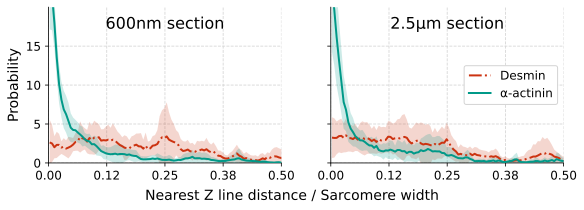

In [20]:
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig)